# IS6400 · Week 4 assignment

**LI Binxiong · 60234350**  
Feature selection: Iris classification and Airbnb log-price regression

This notebook continues the current Canvas tutorial. The instructor's 43 original
cells are retained in their original order; my answers begin at **Assignment answers**.
The submission HTML is exported directly with Jupyter nbconvert, preserving
this notebook's cell order, code, explanations and outputs. All added calculations below use the same source files.

| Required question | What I provide | Points in the notebook |
|---|---|---:|
| Q1 | ANOVA F scores, two selected Iris features, and filter/wrapper explanation | 20 |
| Q2 | Two-feature SFS, its search mechanism, and the chosen features | 40 |
| Q3 | Eight Airbnb predictors selected by `f_regression`; why classification tests do not fit | 20 |
| Q4 | Eight predictors selected by random-forest RFE; comparison with Q3 | 20 |

**Extra analysis:** Appendix A checks the greedy search against all six Iris pairs,
estimates Iris accuracy with selection inside cross-validation, and compares the
Airbnb selections on a held-out test set. Its tables and figure have separate A numbers.
These checks support the answers; they do not replace a required question.

**Reading conventions.** In my answers, scores, correlations, errors and proportions
are displayed to six decimal places; very small p-values use scientific notation
with six decimal places. Counts are integers. Calculations use the original, unrounded
values. The preserved instructor section retains its original rounding conventions.
A selected categorical level, such as `city_NYC`, is one encoded predictor, not an entire
original column. Q3 and Q4 use exactly the same encoded candidate matrix.

<style id="notebook-reading-size">
.jp-RenderedMarkdown {font-size:18px; line-height:1.65;}
.jp-RenderedHTMLCommon table, .jp-RenderedHTMLCommon caption {font-size:16px; line-height:1.5;}
.jp-InputArea-editor pre, .jp-OutputArea-output pre {font-size:14px; line-height:1.6;}
</style>

## Before running: find the data without changing the original files

Run the notebook from top to bottom with **Kernel → Restart Kernel and Run All Cells**.
`Path.cwd()` gives the folder Jupyter started in; `.parents` lists its enclosing folders.
The loop below looks for `course_files_export` containing both required datasets.
`break` stops at the first valid folder. If no folder matches, a clear error explains
where to put the data. No data file is written or edited.

The instructor code uses relative filenames. Changing Python's working directory
with `os.chdir(DATA)` makes those filenames resolve correctly. A fixed random seed
also makes the instructor's unfixed random forests reproducible in this full run.

Thread counts are limited inside this kernel to reduce memory use; this does not change system settings or the statistical specification.

In [1]:
from pathlib import Path
import os
# Limit worker threads inside this kernel on a memory-constrained computer.
for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "BLIS_NUM_THREADS"]:
    os.environ[variable] = "1"
import numpy as np

START = Path.cwd().resolve()
candidates = [START]
for parent in [START, *START.parents]:
    candidates.extend([parent / "course_files_export",
                       parent / "IS6400_Business_Data_Analytics/course_files_export"])
for candidate in candidates:
    if (candidate / "iris.txt").is_file() and (candidate / "Airbnb.csv").is_file():
        DATA = candidate
        break
else:
    raise FileNotFoundError("Put iris.txt and Airbnb.csv beside this notebook or in course_files_export.")
os.chdir(DATA)
np.random.seed(42)
print("Data directory:", DATA.name)

Data directory: course_files_export


# Feature Engineering

The following tutorial contains examples of Python code for feature engineering. 
You should refer to the "Feature Engineering" Lecture Note in Week 4.
Reference links to the scikit-learn documentation are provided for a more comprehensive learning experience.

In this tutorial, you will learn how to:

- Conduct univariate feature selection algorithm.
- Understand the Gini Index and Information Gain for evaluating feature importance.

- Conduct recursive feature elimination algorithm.

- Conduct PCA feature reduction algorithm.




> **Note:** Execute code cells with `Shift+Enter`.


## 1.0 Univariate Feature Selection

Univariate feature selection works by selecting the best features based on univariate statistical tests. It can be seen as a preprocessing step to an estimator.

**Key reference:**
- [SelectKBest – scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html)
- [Feature selection – scikit-learn user guide](https://scikit-learn.org/stable/modules/feature_selection.html#univariate-feature-selection)

The following code identify the algorithm SelectKBest from sklearn library.

In [2]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_classif,chi2,f_regression
# f_classif: ANOVA F-value between label/feature for classification tasks.
# chi2: Chi-squared stats of non-negative features for classification tasks.
# f_regression F-value between label/feature for regression tasks.
import pandas as pd

### 1.1 Load your Raw Data

Recall the iris dataset has four features and one class:

- feature 1: sepal length in centimeters
- feature 2: sepal width in centimeters
- feature 3: petal length in centimeters
- feature 4: petal width in centimeters
- class (Setosa, Versicolour, Virginica)



In [3]:
iris = pd.read_csv('iris.txt', header=None)
iris.columns = ['sepal-L', 'sepal-W', 'petal-L', 'petal-W', 'class']
iris  # you get a dataset of 150 objects and 4 features

,sepal-L,sepal-W,petal-L,petal-W,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


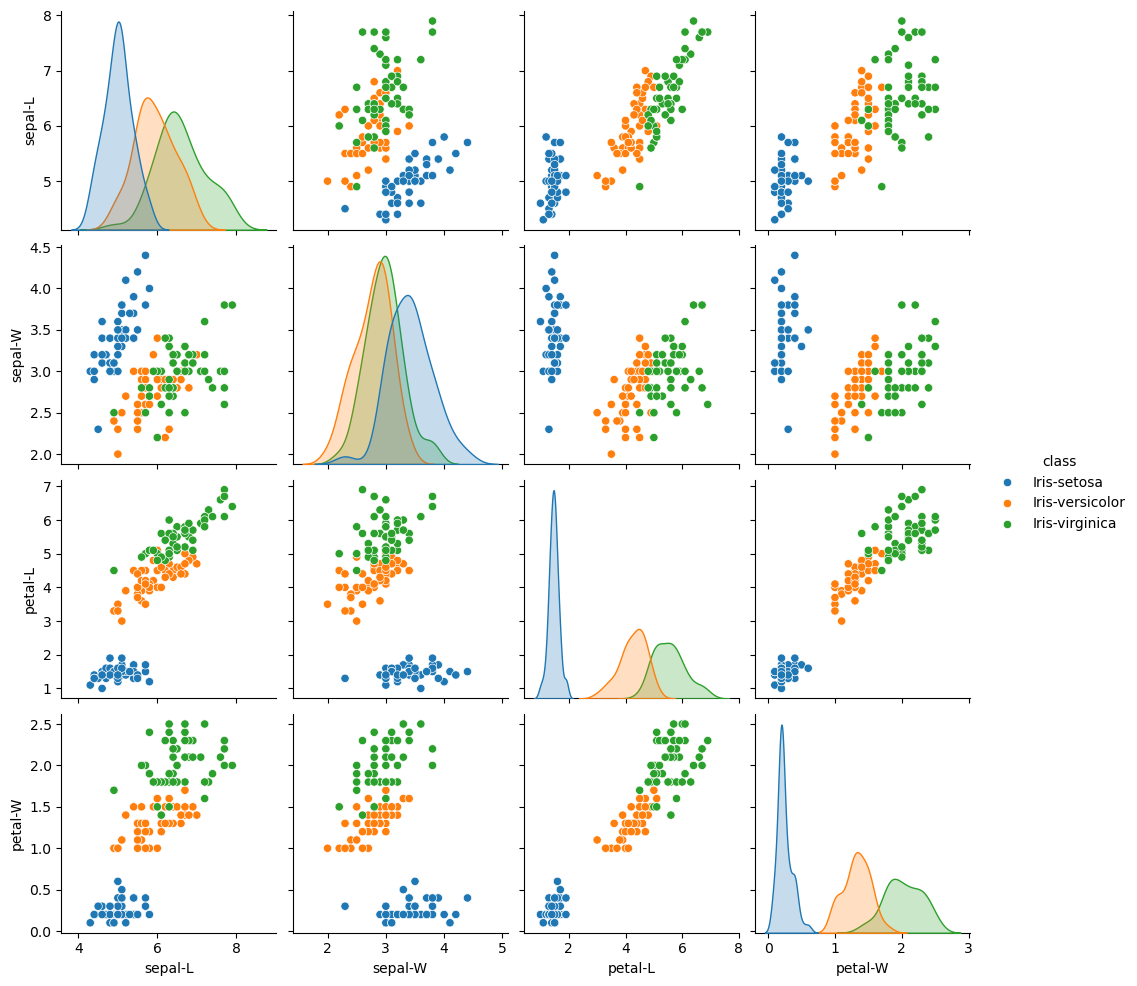

In [4]:
import seaborn as sns #let's take a look at the pairwise plot
sns.pairplot(iris, hue="class") #which features are most representative?

### 1.2 Identify your features and target


In [5]:
features = ['sepal-L', 'sepal-W', 'petal-L', 'petal-W']
target = ['class']
X = iris[features]
y = iris[target]
display(X)

,sepal-L,sepal-W,petal-L,petal-W
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


### 1.3 Select the TWO most representative features from the 4 features using measurement Chi2

The `SelectKBest` is the algorithm you pick from the library.

The `chi2` is the measurement; you can change it to `f_classif` (ANOVA F-value). 

The `k=2` is the number of optimal features you select from the complete set.

**Reference:**
- [SelectKBest – scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html)
- [chi2 – scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.chi2.html)
- [f_classif – scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.f_classif.html)


In [6]:
X_new = SelectKBest(chi2, k=2).fit_transform(X, y)  # we use chi2 as the criteria and select k=2 best features
X_new.shape  # you get a new feature set of dimension k=2

(150, 2)

### 1.4 Check the selected features


In [7]:
display(X_new[0:5, :])  # petal-L and petal-W were selected

array([[1.4, 0.2],
       [1.4, 0.2],
       [1.3, 0.2],
       [1.5, 0.2],
       [1.4, 0.2]])

### 1.5 Feature importance: Gini Index & Information Gain


1. **Gini Index (GINI_split)**: We want to **Minimize** this weighted impurity.
   - $GINI_{split} = \sum_{i=1}^{k} \frac{n_i}{n} GINI(i)$
2. **Information Gain (GAIN_split)**: We want to **Maximize** this entropy reduction.
   - $GAIN_{split} = Entropy(p) - \left( \sum_{i=1}^{k} \frac{n_i}{n} Entropy(i) \right)$

We will evaluate the two PPT cases:
- **Case 1:** `Petal-W <= 0.8` (Perfect split)
- **Case 2:** `Sepal-L <= 6.0` (Imperfect split from the in-class quiz)


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Load Data
iris_filter = pd.read_csv('iris.txt', header=None)
iris_filter.columns = ['sepal-L', 'sepal-W', 'petal-L', 'petal-W', 'class']

# 2. Create a binary target (Setosa vs Non-Setosa) for this specific quiz question
iris_filter['is_setosa'] = (iris_filter['class'] == 'Iris-setosa').astype(int)

# 3. Define Impurity Functions
def calc_gini(y):
    """Calculate Gini Index for a given subset of labels."""
    p = y.value_counts(normalize=True)
    return 1 - np.sum(p ** 2)

def calc_entropy(y):
    """Calculate Entropy for a given subset of labels."""
    p = y.value_counts(normalize=True)
    return -np.sum(p * np.log2(p + 1e-12))

# 4. Define Split Evaluation Function
def evaluate_split(df, feature, threshold, target='is_setosa'):
    # Split the data
    left = df[df[feature] <= threshold]
    right = df[df[feature] > threshold]
    n = len(df)
    n_left, n_right = len(left), len(right)

    # Parent Node Impurity
    parent_gini = calc_gini(df[target])
    parent_entropy = calc_entropy(df[target])

    # Child Node Impurities
    gini_left = calc_gini(left[target]) if n_left else 0
    gini_right = calc_gini(right[target]) if n_right else 0
    
    entropy_left = calc_entropy(left[target]) if n_left else 0
    entropy_right = calc_entropy(right[target]) if n_right else 0

    # Weighted Impurity (GINI_split) - Lower is better
    gini_split = (n_left / n) * gini_left + (n_right / n) * gini_right

    # Information Gain (GAIN_split) - Higher is better
    gain_split = parent_entropy - ((n_left / n) * entropy_left + (n_right / n) * entropy_right)

    return {
        'Feature': feature,
        'Threshold': threshold,
        'n_left': n_left,
        'n_right': n_right,
        'Parent_Gini': round(parent_gini, 4),
        'GINI_split': round(gini_split, 4), # Want to minimize
        'Parent_Entropy': round(parent_entropy, 4),
        'GAIN_split': round(gain_split, 4)   # Want to maximize
    }

# 5. Evaluate the Two PPT Cases
results = pd.DataFrame([
    evaluate_split(iris_filter, 'petal-W', 0.8),
    evaluate_split(iris_filter, 'sepal-L', 6.0)
])

# 6. Display Results
display(results)

,Feature,Threshold,n_left,n_right,Parent_Gini,GINI_split,Parent_Entropy,GAIN_split
0,petal-W,0.8,50,100,0.4444,0.0000,0.9183,0.9183
1,sepal-L,6.0,89,61,0.4444,0.2921,0.9183,0.3315


###  Visualize the two splits to understand "Perfect" vs "Imperfect"


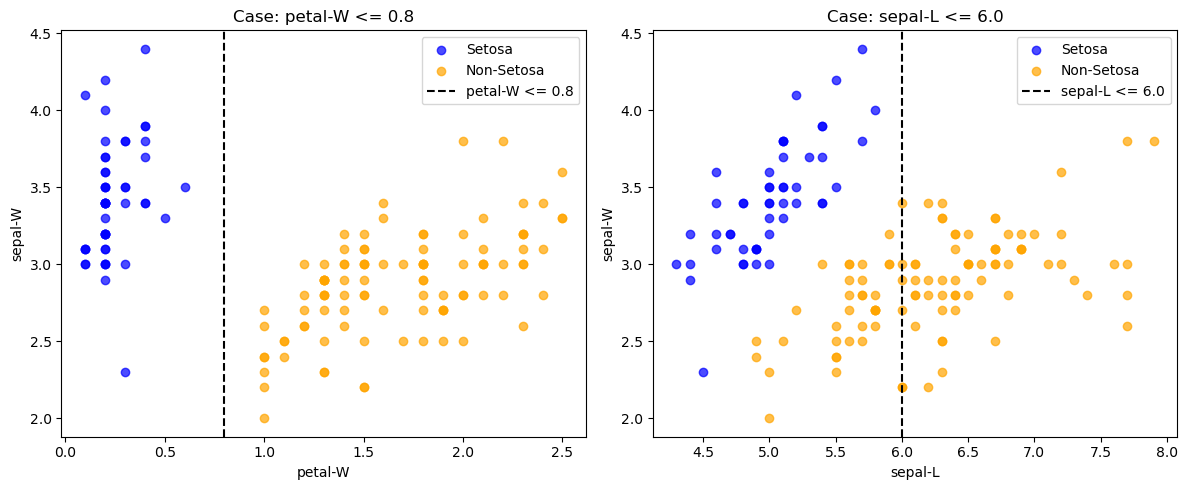

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (feature, threshold) in zip(axes, [('petal-W', 0.8), ('sepal-L', 6.0)]):
    # Plot Setosa
    setosa = iris_filter[iris_filter['is_setosa'] == 1]
    non_setosa = iris_filter[iris_filter['is_setosa'] == 0]
    
    ax.scatter(setosa[feature], setosa['sepal-W'], color='blue', label='Setosa', alpha=0.7)
    ax.scatter(non_setosa[feature], non_setosa['sepal-W'], color='orange', label='Non-Setosa', alpha=0.7)
    
    # Draw threshold line
    ax.axvline(threshold, color='black', linestyle='--', label=f'{feature} <= {threshold}')
    
    ax.set_xlabel(feature)
    ax.set_ylabel('sepal-W')
    ax.set_title(f'Case: {feature} <= {threshold}')
    ax.legend()

plt.tight_layout()
plt.show()

### Interpretation of Results

Based on the table and plots above, we can confirm the lecture's conclusions:

1. **Case 1: `Petal-W <= 0.8` (Perfect Split)**
   - **GINI_split** is extremely low (close to 0).
   - **GAIN_split** is very high.
   - *Reason*: This threshold perfectly isolates the Setosa class. The left node contains almost entirely Setosa, and the right node contains almost entirely Non-Setosa. The weighted impurity is minimized, and information gain is maximized.

2. **Case 2: `Sepal-L <= 6.0` (Imperfect Split)**
   - **GINI_split** is higher.
   - **GAIN_split** is lower.
   - *Reason*: This threshold splits the data, but both the left and right nodes contain a mix of Setosa and Non-Setosa. Because the child nodes are not pure, the weighted impurity is higher, and the reduction in entropy (Information Gain) is lower.


## 2. Feature Selection — use Wrapper model to measure feature importance

The `SelectFromModel` from the sklearn library is a kind of Wrapper model. The algorithm selected for feature importance measurement is `ExtraTreesClassifier`.

**Reference:**
- [SelectFromModel – scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectFromModel.html)
- [ExtraTreesClassifier – scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesClassifier.html)


In [10]:
from sklearn.ensemble import ExtraTreesClassifier
#This class implements a meta estimator that fits a number of randomized decision trees 
#(a.k.a. extra-trees) on various sub-samples of the dataset and 
#uses averaging to improve the predictive accuracy and control over-fitting.

from sklearn.feature_selection import SelectFromModel


### 2.1 We will generate the dataset

In [11]:
iris = pd.read_csv('iris.txt',header=None)
iris.columns=['sepal-L','sepal-W','petal-L','petal-W','class']
features=['sepal-L','sepal-W','petal-L','petal-W']
target=['class']
X=iris[features]
y=iris[target]
X=X.values
y=y.values.ravel()  #please note y is a one-dimensional data, we need to use ravel() to reshape it to (n,) 

In [12]:
y.shape

(150,)

### 2.2 We identify a classifier and use the classifier to measure feature importance



In [13]:
clf = ExtraTreesClassifier(n_estimators=50)  # get the model from library
clf = clf.fit(X, y)  # fit your data
clf.feature_importances_  # now we can get the feature importance score from model

array([0.08857906, 0.05433906, 0.42426568, 0.43281621])

### 2.3 Select your feature subset from SelectFromModel

Reference: <https://scikit-learn.org/stable/modules/feature_selection.html#select-from-model>


In [14]:
selection = SelectFromModel(clf, prefit=True)
X_new = selection.transform(X)
display(X_new[0:5, :])

array([[1.4, 0.2],
       [1.4, 0.2],
       [1.3, 0.2],
       [1.5, 0.2],
       [1.4, 0.2]])

### 2.4 Recursive Feature Elimination (RFE)

Given an external estimator that assigns weights to features (e.g., the coefficients of a linear model), recursive feature elimination (RFE) is to select features by recursively considering smaller and smaller sets of features. First, the estimator is trained on the initial set of features and the importance of each feature is obtained either through a `coef_` attribute or through a `feature_importances_` attribute. Then, the least important features are pruned from the current set of features. That procedure is recursively repeated on the pruned set until the desired number of features to select is eventually reached.

**Reference:**
- [RFE – scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html)


In [15]:
from sklearn.feature_selection import RFE
clf = ExtraTreesClassifier(n_estimators=50)
selection = RFE(estimator=clf, n_features_to_select=2, step=1)
selection.fit(X,y)
X_new=selection.transform(X)
display(X_new[0:5,:])

array([[1.4, 0.2],
       [1.4, 0.2],
       [1.3, 0.2],
       [1.5, 0.2],
       [1.4, 0.2]])

In [16]:
# alternatively, put fit and transform together:
X_new = selection.fit_transform(X, y)
display(X_new[0:5, :])

array([[1.4, 0.2],
       [1.4, 0.2],
       [1.3, 0.2],
       [1.5, 0.2],
       [1.4, 0.2]])

## 3. Feature Reduction — Principle Component Analysis (PCA)

Principal Component Analysis (PCA) applied to this data identifies the combination of attributes (principal components, or directions in the feature space) that account for the most variance in the data. Here we plot the different samples on the 2 first principal components.

**Reference:**
- [PCA – scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
- [PCA – scikit-learn user guide](https://scikit-learn.org/stable/modules/decomposition.html#pca)

We first get PCA algorithm from the library and then map the 4-dimensional feature set into a 2-dimensional feature set:

In [17]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

We map it to a two dimensional space

In [18]:
iris = pd.read_csv('iris.txt', header=None)
iris.columns = ['sepal-L', 'sepal-W', 'petal-L', 'petal-W', 'class']
X = iris[['sepal-L', 'sepal-W', 'petal-L', 'petal-W']].values
pca = PCA(n_components=2)  # we select PCA algorithm with 2 dimensions
z = pca.fit(X).transform(X)

In [19]:
display(z[:5, :])

array([[-2.68420713,  0.32660731],
       [-2.71539062, -0.16955685],
       [-2.88981954, -0.13734561],
       [-2.7464372 , -0.31112432],
       [-2.72859298,  0.33392456]])

In [20]:
iris['z1'] = z[:, 0]
iris['z2'] = z[:, 1]
iris.head()

,sepal-L,sepal-W,petal-L,petal-W,class,z1,z2
0,5.1,3.5,1.4,0.2,Iris-setosa,-2.684207,0.326607
1,4.9,3.0,1.4,0.2,Iris-setosa,-2.715391,-0.169557
2,4.7,3.2,1.3,0.2,Iris-setosa,-2.889820,-0.137346
3,4.6,3.1,1.5,0.2,Iris-setosa,-2.746437,-0.311124
4,5.0,3.6,1.4,0.2,Iris-setosa,-2.728593,0.333925


We scatter plot the data in a the new space of z

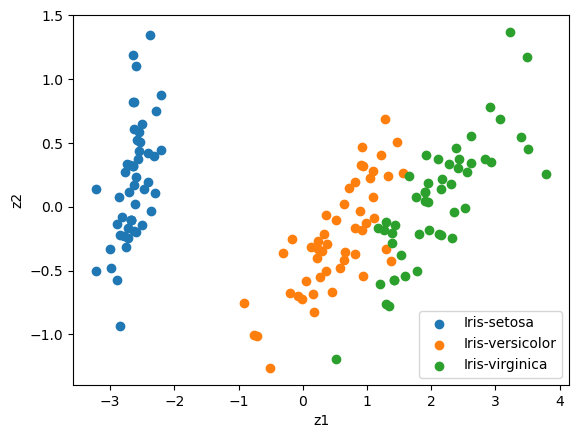

In [21]:
import matplotlib.pyplot as plt
groups = iris.groupby("class")
for name, group in groups:
    plt.scatter(group['z1'],group['z2'], marker="o", label=name)
plt.xlabel('z1')
plt.ylabel('z2')
plt.legend()
plt.show()

---
# Week 4 Assignment



### Question 1
use f_classif as your evaluation measurement and redo the feature selection in Univariate feature selection. what does "f_classif" represent? Is this a filter model or wrapper model? (20 points). 


### Question 2
Read documentation of "SequentialFeatureSelector" and use it to select the top TWO features. What is the mechnism of this tool? What are these two optimal features? (40 points)

document: https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SequentialFeatureSelector.html

### Question 3
Load `Airbnb.csv`on Canvas-Week4 Homepage. The target is `log_price` (regression). Use `SelectKBest` with `f_regression` to select the top 8 features. Print the selected feature names. Briefly explain why `chi2` and `f_classif` are not appropriate here. (20 Points)


### Question 4
Load `Airbnb.csv`on Canvas-Week4 Homepage. The target is `log_price` (regression). Use `RandomForestRegressor` with `RFE` to select 8 features. Print the selected feature names. Briefly compare them with your answer in Question 3 and discuss any difference. (20 Points)

document: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html#sklearn.ensemble.RandomForestRegressor

# Assignment answers

## Shared tools: tables, randomness and model evaluation

`import` makes a library available; `from ... import ...` brings a particular tool
into the notebook. A variable is a name for a value, so `SEED = 42` stores the value
used in each random split. A function, defined with `def`, groups a small reusable
operation. Here `show_table` only formats output: it never changes stored numbers.

`Pipeline` runs steps in order. Putting standardisation inside the classifier's
pipeline makes each cross-validation fold learn its own mean and scale from its
training rows. A held-out fold is used for scoring, not fitting those quantities.
`clone` creates an unfitted copy, which keeps a later comparison from reusing an
earlier model's fitted state.

In [22]:
import itertools
import json
import hashlib
import platform
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, f_classif, f_regression, SequentialFeatureSelector, RFE
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
pd.set_option("display.float_format", lambda value: f"{value:.6f}")
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

def show_table(frame, caption, scientific=()):
    formats = {column: "{:.6f}" for column in frame.select_dtypes(include="floating").columns}
    for column in scientific:
        formats[column] = "{:.6e}"
    display(frame.style.format(formats, na_rep="—").hide(axis="index").set_caption(caption))

print("Python", platform.python_version(), "| pandas", pd.__version__,
      "| NumPy", np.__version__, "| scikit-learn", sklearn.__version__)

Python 3.12.3 | pandas 2.3.3 | NumPy 1.26.4 | scikit-learn 1.5.1


## Q1 · Univariate selection with ANOVA F (20 points)

### 1.1 What does `f_classif` measure?

One Iris row describes one flower. The four measurements are the **features**;
the species label is the **target**. A univariate test looks at one measurement
at a time. `f_classif` calculates the one-way analysis-of-variance (ANOVA) F statistic:
how far the species means differ, relative to variation among flowers within each
species. A large F score means a useful separation of group means in this sample.

$$
F_j=\frac{\sum_{g=1}^{G}n_g(\bar{x}_{gj}-\bar{x}_j)^2/(G-1)}{\sum_{g=1}^{G}\sum_{i\in g}(x_{ij}-\bar{x}_{gj})^2/(N-G)}
$$

| Symbol | Meaning |
|---|---|
| $j$ | One feature, for example petal length |
| $G$ and $N$ | Number of species and number of flowers; here 3 and 150 |
| $n_g$ | Number of flowers in species $g$ |
| $x_{ij}$ | Measurement of feature $j$ on flower $i$ |
| $\bar{x}_{gj}$ and $\bar{x}_j$ | Species mean and overall mean of the measurement |

For a simple numerical example, between-group mean square 12 and within-group
mean square 2 give $F=12/2=6$. This is a ratio, not a percentage or a model's accuracy.
The accompanying p-value tests equal group means under the ANOVA assumptions;
it does not measure effect size or causality. The F ranking remains useful descriptively
even when the ideal independence, normality and equal-variance assumptions are uncertain.

### 1.2 Load the original four measurements and select two

`read_csv(..., header=None, names=...)` supplies the column names missing from `iris.txt`.
`iris_q[iris_features]` selects four columns and keeps a two-dimensional table.
`iris_q["class"]` selects a one-dimensional target. This shape matters: sklearn expects
one label per row, not a table containing several target columns.

`SelectKBest(score_func=f_classif, k=2)` creates a selector but does not fit it yet.
`.fit(X, y)` computes scores from the supplied data. `.get_support()` returns one
`True`/`False` value per candidate column. Indexing the column names with that mask
prints the names, rather than just an unexplained numeric matrix.

In [23]:
iris_features = ["sepal-L", "sepal-W", "petal-L", "petal-W"]
iris_q = pd.read_csv(DATA / "iris.txt", header=None, names=iris_features + ["class"])
X_iris = iris_q[iris_features]
y_iris = iris_q["class"]
assert X_iris.shape == (150, 4) and y_iris.nunique() == 3
assert not iris_q.isna().any().any()

anova_selector = SelectKBest(score_func=f_classif, k=2)
anova_selector.fit(X_iris, y_iris)
anova_names = X_iris.columns[anova_selector.get_support()].tolist()
anova_table = pd.DataFrame({"Feature": iris_features,
                            "F score": anova_selector.scores_,
                            "p-value": anova_selector.pvalues_,
                            "Selected": anova_selector.get_support()})
show_table(anova_table.sort_values("F score", ascending=False), "Table 1. Iris ANOVA F ranking", ["p-value"])
print("Q1 selected features:", anova_names)
print("Transformed shape:", anova_selector.transform(X_iris).shape)

Feature,F score,p-value,Selected
petal-L,1179.034328,3.051976e-91,True
petal-W,959.324406,4.376957e-85,True
sepal-L,119.264502,1.669669e-31,False
sepal-W,47.364461,1.327917e-16,False


Q1 selected features: ['petal-L', 'petal-W']
Transformed shape: (150, 2)


### 1.3 Read the scores and classify the method

The two largest scores in Table 1 identify the selected measurements. The transformed
array has 150 rows and two columns: selection removes measurements, not flowers.
All four p-values are small, but we still keep only the two highest F scores because
the requested `k` is two. With several tests, a small p-value alone is not a complete
model-selection rule.

**This is a filter method.** The ranking comes from a statistical test and does not
repeatedly train a classifier to decide which subset predicts best. It uses the labels,
so “filter” does not mean “unsupervised”. A wrapper, such as SFS in Q2, evaluates
subsets through a specified predictive model.

A limitation is that F scores test each feature separately. Two highly correlated
measurements can both rank well while contributing similar information. Conversely,
a feature useful only through interaction with another one can look weak alone.
These are reasons to compare selection rules, not reasons to discard the Q1 result.

The p-values describe the ANOVA null model; correlated tests and model selection limit their interpretation as independent evidence.

## Q2 · SequentialFeatureSelector: two Iris features (40 points)

### 2.1 Define what “best” means before searching

The question does not fix an estimator, a search direction or a scoring rule.
I use **forward SFS**, standardised logistic regression and mean five-fold stratified
cross-validation accuracy. Logistic regression here is a classifier, despite its name:
it learns class probabilities and predicts the flower species. `StandardScaler`
centres each measurement and divides it by its training-fold standard deviation,
so a centimetre measurement's numerical scale does not dominate regularisation.

“Stratified” means each fold keeps approximately the same species proportions.
`shuffle=True` mixes row order before forming folds; `random_state=42` fixes that
shuffle. In a five-fold comparison, each model fits four folds and predicts the fifth.
The selection score averages those five accuracies. It is used to choose features,
so it is not an independent estimate of final predictive accuracy.

### 2.2 Fit SFS and print the selected names

`make_pipeline` joins the scaler and classifier. `max_iter=3000` is a convergence
limit, not a requested number of trees or folds; `C=1.0` fixes the regularisation setting.
`n_features_to_select=2` is the stopping rule. `scoring="accuracy"` makes a larger
fraction of correct species predictions better. `.fit` carries out the search;
`.get_support()` then maps its decision back to the four original names.

In [24]:
iris_model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000, random_state=SEED))
iris_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
sfs = SequentialFeatureSelector(estimator=iris_model, n_features_to_select=2,
                                direction="forward", scoring="accuracy", cv=iris_cv, n_jobs=1)
sfs.fit(X_iris, y_iris)
sfs_names = X_iris.columns[sfs.get_support()].tolist()
print("Q2 selected features:", sfs_names)
print("Transformed shape:", sfs.transform(X_iris).shape)

Q2 selected features: ['sepal-L', 'petal-W']
Transformed shape: (150, 2)


### 2.3 Make the two greedy steps visible

Forward selection starts with no feature. It trains and scores four one-feature
models, keeps the highest-scoring feature, then tries adding each of the three
remaining features. The best second step is retained, and the search stops at two.
`for` repeats the same operation for each candidate; `list` holds the proposed subset.
`cross_val_score` runs the five training/validation comparisons. `.mean()` averages
their scores. The following transparent replay uses the same model and folds as SFS.

If scores tie, the first feature in the supplied order wins, consistent with this
implementation. `np.argmax` returns the position of the largest score; the integer
is an index, not an accuracy. The assertion below checks that the replay agrees with
the actual sklearn selector rather than presenting a separate hand-picked result.

In [25]:
chosen = []
search_rows = []
for step in [1, 2]:
    remaining = [name for name in iris_features if name not in chosen]
    means = []
    for candidate in remaining:
        subset = chosen + [candidate]
        scores = cross_val_score(iris_model, X_iris[subset], y_iris, cv=iris_cv, scoring="accuracy")
        means.append(float(scores.mean()))
        search_rows.append({"Step": step, "Candidate subset": " + ".join(subset),
                            "CV accuracy": float(scores.mean()), "Fold SD": float(scores.std(ddof=1))})
    chosen.append(remaining[int(np.argmax(means))])
assert set(chosen) == set(sfs_names)
search_table = pd.DataFrame(search_rows)
show_table(search_table, "Table 2. Forward SFS candidate scores (selection data, not a test set)")
print("Search order:", chosen)

Step,Candidate subset,CV accuracy,Fold SD
1,sepal-L,0.746667,0.112052
1,sepal-W,0.540000,0.064118
1,petal-L,0.946667,0.038006
1,petal-W,0.960000,0.043461
2,petal-W + sepal-L,0.960000,0.043461
2,petal-W + sepal-W,0.953333,0.050553
2,petal-W + petal-L,0.953333,0.050553


Search order: ['petal-W', 'sepal-L']


In [26]:
selected_cv = cross_val_score(iris_model, X_iris[sfs_names], y_iris, cv=iris_cv, scoring="accuracy")
display(Markdown(f"**Answer.** Under the stated model and folds, SFS selects **{', '.join(sfs_names)}** "
                 f"with selection-CV accuracy **{selected_cv.mean():.6f}**. The first search choice is "
                 f"**{chosen[0]}**, followed by **{chosen[1]}**. The ANOVA selection in Q1 "
                 f"{'agrees' if set(anova_names) == set(sfs_names) else 'differs'} with this pair."))

**Answer.** Under the stated model and folds, SFS selects **sepal-L, petal-W** with selection-CV accuracy **0.960000**. The first search choice is **petal-W**, followed by **sepal-L**. The ANOVA selection in Q1 differs with this pair.

SFS is a **wrapper**: its answer depends on the classifier and the validation score,
not just a separate F statistic. “Optimal” in this answer means the greedy choice
under those stated settings. SFS does not revisit an earlier addition and cannot
guarantee the best of all possible feature subsets. On four features we can check
all six pairs; Appendix A1 performs that check and discusses ties. On many features,
that exhaustive search would become much more expensive.

For biological interpretation, the selected pair describes the flower parts whose
joint measurements help distinguish species in this sample. A good prediction
does not establish a biological causal effect. Appendix A2 evaluates the entire
selection procedure on folds that were not used to choose their features.

## Q3 · Eight Airbnb features with `f_regression` (20 points)

### 3.1 Set the target and prevent leakage

`log_price` is a continuous response, so this is **regression**, not species
classification. I remove `id`: it identifies a listing but has no defensible
numerical ordering for pricing. I also exclude the target from the predictors.
Including `log_price` or a price reconstructed from it would leak the answer.

The remaining 13 original fields include numeric values, a Boolean cleaning-fee
indicator and text categories. Categories must become numeric before either
selector can use them. One-hot encoding makes one indicator per category: for
example, `city_NYC` is 1 for a New York listing and 0 otherwise. It does not pretend
that one city is twice another. Both selectors later receive the **same encoded
columns**, so their eight-feature lists can be compared fairly.

I split the rows 80:20 once, before learning missing-value replacements or categories.
The test set is not used to select features. Numeric missing values use the training
median; missing text values get an explicit `Missing` category. `handle_unknown="ignore"`
represents an unseen test category by zeros instead of crashing. I retain all levels
(`drop=None`): the comparisons use forests, and a complete indicator representation
avoids making the selection depend on an arbitrarily omitted reference category.

### 3.2 Load, split and inspect the inputs

`.drop(columns=[...])` returns the predictors without changing the source CSV.
`train_test_split` returns training features, test features and their matching targets.
`test_size=0.20` reserves one fifth of rows. The count check confirms that no row
disappears; the index check confirms that training and test rows do not overlap.

In [27]:
airbnb = pd.read_csv(DATA / "Airbnb.csv")
X_air = airbnb.drop(columns=["id", "log_price"])
y_air = airbnb["log_price"]
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_air, y_air, test_size=0.20, random_state=SEED)
assert len(X_train_raw) + len(X_test_raw) == len(airbnb) == 68133
assert set(X_train_raw.index).isdisjoint(X_test_raw.index)
assert y_air.notna().all() and np.isfinite(y_air).all()
numeric = X_air.select_dtypes(include="number").columns.tolist()
binary = ["cleaning_fee"]
categorical = [name for name in X_air.columns if name not in numeric + binary]
missing_table = pd.DataFrame({"Original feature": X_air.columns,
                              "Missing rows": X_air.isna().sum().to_numpy(),
                              "Representation": ["numeric" if c in numeric else "Boolean 0/1" if c in binary
                                                  else "one-hot category" for c in X_air.columns]})
show_table(missing_table, "Table 3. Airbnb candidate fields and missing values (descriptive counts)")
print("Train rows:", len(X_train_raw), "| Test rows:", len(X_test_raw), "| Original candidate fields:", X_air.shape[1])

Original feature,Missing rows,Representation
property_type,0,one-hot category
accommodates,0,numeric
bathrooms,0,numeric
bed_type,0,one-hot category
cancellation_policy,0,one-hot category
cleaning_fee,0,Boolean 0/1
city,0,one-hot category
host_has_profile_pic,180,one-hot category
host_identity_verified,180,one-hot category
number_of_reviews,0,numeric


Train rows: 54506 | Test rows: 13627 | Original candidate fields: 13


`ColumnTransformer` applies different steps to named groups of columns, then joins
their outputs. The numeric branch fills gaps with a median. The categorical branch
fills missing values and one-hot encodes text. The Boolean branch passes through
the existing true/false indicator, which becomes 1/0 in the numeric array.

`.fit_transform(X_train_raw)` learns preprocessing from training rows and transforms
them. `.transform(X_test_raw)` uses those same learned rules without fitting again.
`get_feature_names_out()` returns the actual encoded names. `verbose_feature_names_out=False`
omits technical branch prefixes, not category names. The `assert` statements check
one name per transformed column and no missing/infinite values. They test the input
contract, not whether the model is accurate.

In [28]:
preprocess = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric),
    ("categorical", make_pipeline(SimpleImputer(strategy="constant", fill_value="Missing"),
                                  OneHotEncoder(handle_unknown="ignore", drop=None, sparse_output=False)), categorical),
    ("binary", "passthrough", binary),
], verbose_feature_names_out=False)
X_train_array = preprocess.fit_transform(X_train_raw)
X_test_array = preprocess.transform(X_test_raw)
encoded_names = preprocess.get_feature_names_out()
X_train = pd.DataFrame(X_train_array, columns=encoded_names, index=X_train_raw.index)
X_test = pd.DataFrame(X_test_array, columns=encoded_names, index=X_test_raw.index)
assert X_train.shape[1] == len(encoded_names) == X_test.shape[1]
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_test.to_numpy()).all()
print("Encoded candidate predictors:", len(encoded_names))
print("Target:", y_train.name, "| Example city indicators:", [n for n in encoded_names if n.startswith("city_")])

Encoded candidate predictors: 33
Target: log_price | Example city indicators: ['city_Boston', 'city_Chicago', 'city_DC', 'city_LA', 'city_NYC', 'city_SF']


### 3.3 Compute the F scores and print the eight selected names

`f_regression` evaluates each predictor's linear association with the continuous
target. If $r_j$ is its training-sample Pearson correlation with `log_price` and
$n$ is the number of training rows, the single-predictor statistic is

$$
F_j=\frac{r_j^2}{1-r_j^2}(n-2).
$$

For example, $r_j=0.5$ and $n=100$ give $F_j=32.666667$.
Squaring means a strong negative association can rank just as highly as a strong
positive one. The score does not tell us the direction, so Table 4 also reports
the signed correlation. This formula describes the centred, nonconstant case;
sklearn handles constant columns separately.

`.scores_` and `.pvalues_` are results created by fitting; the trailing underscore
marks fitted attributes. `k=8` keeps exactly eight encoded predictors. I sort the
selected rows by F score for readability, but use the Boolean support mask for
subsequent model inputs. No displayed rounding affects selection.

In [29]:
f_selector = SelectKBest(score_func=f_regression, k=8)
f_selector.fit(X_train, y_train)
f_mask = f_selector.get_support()
f_names = encoded_names[f_mask].tolist()
correlations = X_train.corrwith(y_train)
f_table_all = pd.DataFrame({"Encoded feature": encoded_names, "F score": f_selector.scores_,
                            "p-value": f_selector.pvalues_, "Correlation": correlations.to_numpy(),
                            "Selected": f_mask})
f_table = f_table_all.loc[f_mask].sort_values("F score", ascending=False)
assert f_mask.sum() == 8
show_table(f_table, "Table 4. Eight Airbnb features selected by f_regression", ["p-value"])
print("Q3 selected features:", f_names)

Encoded feature,F score,p-value,Correlation,Selected
accommodates,27527.138022,0.000000e+00,0.579284,True
bedrooms,16728.321134,0.000000e+00,0.484605,True
beds,15731.839869,0.000000e+00,0.473272,True
bathrooms,9386.971956,0.000000e+00,0.383304,True
city_SF,1424.872074,7.916224e-308,0.159614,True
cancellation_policy_strict,949.612130,9.695032e-207,0.130860,True
cleaning_fee,775.456777,1.811345e-169,0.118440,True
cancellation_policy_flexible,567.014512,1.089006e-124,-0.101470,True


Q3 selected features: ['accommodates', 'bathrooms', 'bedrooms', 'beds', 'cancellation_policy_flexible', 'cancellation_policy_strict', 'city_SF', 'cleaning_fee']


### 3.4 Why `chi2` and `f_classif` do not fit this target

Both tests are designed for a **categorical class label**. `chi2` measures dependence
between nonnegative feature values and classes; `f_classif` compares feature means
across classes. Here `log_price` is a continuous quantity to predict. Treating each
price as a class would change the question and can leave classes with too few rows.
The fact that one-hot indicators are nonnegative does not turn the target into a class.
Arbitrarily binning prices would also discard information and solve a different task.

Table 4 answers the question at the encoded-column level. Two levels of a field
can both be selected; thus eight selected columns need not mean eight distinct
original fields. This is an explicit modelling choice, since the question does not
specify categorical encoding. Each selected dummy remains interpretable as a
named listing characteristic. The signed correlations are marginal associations;
they do not control for location, size or other confounding characteristics.

Large F scores in a dataset this size are not proof of useful out-of-sample gains.
Correlated capacity measures may duplicate information, and a rare category may
have less stable evidence than a common one. Q4 changes the selection rule;
Appendix A3 checks whether that change matters for predictive error.

A p-value displayed as `0.000000e+00` is numerical underflow at this sample size, not a claim that the probability is exactly zero. I use F scores for the requested ranking.

## Q4 · Eight Airbnb features with random-forest RFE (20 points)

### 4.1 Fit the requested estimator and eliminate features recursively

A random forest averages predictions from many decision trees. A tree can split
price-related groups at thresholds and combine several predictors; this can capture
nonlinear patterns that a single-feature linear F test misses. Forest impurity
importance measures the reduction in training squared error credited to each feature.
It is model-dependent and is not a causal effect.

RFE means **recursive feature elimination**. It fits a forest on the current columns,
removes the least important column, refits on the remaining columns, and repeats
until eight remain. Unlike SFS, this RFE uses fitted importance rather than a
cross-validation score to decide each removal. It is a wrapper around the estimator;
the forest itself supplies the embedded importance measure.

`n_estimators=120` sets the number of trees. `max_depth=12` limits each tree's depth,
and `min_samples_leaf=5` discourages splits supported by very few observations.
`max_features=1.0` allows all current columns to be considered at a split. These
settings are fixed before inspecting test outcomes. `n_jobs=1` uses one CPU worker;
it affects runtime, not the interpretation. `step=1` removes one feature per round,
so the selection follows the stated elimination mechanism without batch removals.

The cell can take several minutes because it trains many forests. Let it finish;
do not run later cells while this one is still active. `.ranking_ == 1` means retained,
not “tied as the most important”. Among the retained columns, the final forest's
importance gives a separate relative ranking.

In [30]:
forest = RandomForestRegressor(n_estimators=120, max_depth=12, min_samples_leaf=5,
                               max_features=1.0, random_state=SEED, n_jobs=1)
rfe = RFE(estimator=forest, n_features_to_select=8, step=1)
rfe.fit(X_train, y_train)
rfe_mask = rfe.get_support()
rfe_names = encoded_names[rfe_mask].tolist()
assert rfe_mask.sum() == 8 and np.all(rfe.ranking_[rfe_mask] == 1)
rfe_table = pd.DataFrame({"Encoded feature": rfe_names,
                          "Final forest importance": rfe.estimator_.feature_importances_,
                          "RFE rank": rfe.ranking_[rfe_mask]})
show_table(rfe_table.sort_values("Final forest importance", ascending=False),
           "Table 5. Eight Airbnb features retained by random-forest RFE")
print("Q4 selected features:", rfe_names)

Encoded feature,Final forest importance,RFE rank
bedrooms,0.543980,1
accommodates,0.172867,1
bathrooms,0.113346,1
number_of_reviews,0.048408,1
city_SF,0.035595,1
property_type_House,0.035229,1
review_scores_rating,0.030948,1
city_LA,0.019626,1


Q4 selected features: ['accommodates', 'bathrooms', 'number_of_reviews', 'review_scores_rating', 'bedrooms', 'property_type_House', 'city_LA', 'city_SF']


### 4.2 Compare actual selections, not just definitions

The table below distinguishes shared columns from columns retained by only one
method. `set` removes ordering when checking overlap, because column order does
not determine membership. The table keeps the original column order for easy tracing
back to the preprocessing matrix. Both methods used the same training rows, target
and candidate encoding; their difference is the selection criterion.

In [31]:
union_names = [name for name in encoded_names if name in set(f_names) | set(rfe_names)]
comparison = pd.DataFrame({"Encoded feature": union_names,
                            "Q3: f_regression": [name in f_names for name in union_names],
                            "Q4: forest RFE": [name in rfe_names for name in union_names]})
show_table(comparison, "Table 6. Feature membership in Q3 and Q4")
shared = sorted(set(f_names) & set(rfe_names))
only_f = sorted(set(f_names) - set(rfe_names))
only_rfe = sorted(set(rfe_names) - set(f_names))
display(Markdown(f"The methods share **{len(shared)} of eight** encoded predictors: "
                 f"**{', '.join(shared)}**. F selection alone keeps **{', '.join(only_f) or 'none'}**; "
                 f"RFE alone keeps **{', '.join(only_rfe) or 'none'}**."))

Encoded feature,Q3: f_regression,Q4: forest RFE
accommodates,True,True
bathrooms,True,True
number_of_reviews,False,True
review_scores_rating,False,True
bedrooms,True,True
beds,True,False
property_type_House,False,True
cancellation_policy_flexible,True,False
cancellation_policy_strict,True,False
city_LA,False,True


The methods share **4 of eight** encoded predictors: **accommodates, bathrooms, bedrooms, city_SF**. F selection alone keeps **beds, cancellation_policy_flexible, cancellation_policy_strict, cleaning_fee**; RFE alone keeps **city_LA, number_of_reviews, property_type_House, review_scores_rating**.

F selection ranks each column's **marginal linear relationship** with price. RFE
reevaluates a **joint nonlinear model** after each removal. Capacity fields can all
have high F scores because they describe related aspects of property size. A forest
may rely on a different mix of capacity, location, review activity and policy indicators
because their thresholds or combinations improve its fitted predictions.

I therefore read shared features as agreement under two particular criteria, and
differences as evidence about model dependence. I would not call one list “the true
drivers of price”. Correlated predictors can share or substitute importance; tree
impurity importance can also favour continuous variables or variables offering many
possible split points. One-hot encoding divides a categorical field's evidence among
levels, whereas a continuous field occupies one column. Eight columns are also a
requirement of this exercise, not an empirically tuned optimal feature count.

**My judgement:** selection should be judged by the question we need to answer.
F scores are a clear, cheap screen for individual linear association. RFE is useful
when the final model is a forest and joint patterns matter. Neither list by itself
demonstrates predictive quality. Appendix A3 compares both with an all-feature forest
and a constant baseline on the test rows that were kept out of feature selection.

# Appendix A · Additional checks and interpretation

These analyses are additions to Q1–Q4. Appendix tables use `Table A1`, `Table A2`,
`Table A3`, `Table A4` and `Table A5`; the additional chart is `Figure A1`.

## A1 · Did the greedy Iris search miss a better pair?

There are only six ways to choose two of four measurements, so exhaustive comparison
is affordable here. `itertools.combinations(..., 2)` lists each distinct pair once.
Each pair is scored with the same five folds and classifier as Q2. This isolates
search behaviour from a change in evaluation settings. These remain selection scores,
so they cannot establish generalisation on their own.

In [32]:
pair_rows = []
for pair in itertools.combinations(iris_features, 2):
    scores = cross_val_score(iris_model, X_iris[list(pair)], y_iris, cv=iris_cv, scoring="accuracy")
    pair_rows.append({"Pair": " + ".join(pair), "CV accuracy": float(scores.mean()),
                      "Fold SD": float(scores.std(ddof=1)), "Selected by SFS": set(pair) == set(sfs_names)})
pair_table = pd.DataFrame(pair_rows).sort_values("CV accuracy", ascending=False, kind="stable")
show_table(pair_table, "Table A1. All six Iris pairs, under the Q2 selection criterion")
best_pair_score = pair_table["CV accuracy"].max()
tied_pairs = pair_table.loc[np.isclose(pair_table["CV accuracy"], best_pair_score), "Pair"].tolist()
display(Markdown(f"SFS's chosen pair {'matches' if np.isclose(selected_cv.mean(), best_pair_score) else 'does not match'} "
                 f"the largest mean score **{best_pair_score:.6f}**. The highest-scoring pair(s) are "
                 f"**{'; '.join(tied_pairs)}**. This verifies this small search problem; "
                 "it does not turn a greedy algorithm into a general exhaustive-search guarantee."))

Pair,CV accuracy,Fold SD,Selected by SFS
sepal-L + petal-W,0.960000,0.043461,True
sepal-W + petal-W,0.953333,0.050553,False
petal-L + petal-W,0.953333,0.050553,False
sepal-L + petal-L,0.940000,0.036515,False
sepal-W + petal-L,0.920000,0.055777,False
sepal-L + sepal-W,0.813333,0.090062,False


SFS's chosen pair matches the largest mean score **0.960000**. The highest-scoring pair(s) are **sepal-L + petal-W**. This verifies this small search problem; it does not turn a greedy algorithm into a general exhaustive-search guarantee.

## A2 · Evaluate Iris selection inside cross-validation

Choosing features on all 150 flowers before reporting the same folds' accuracy can
give an optimistic impression. Here an outer five-fold loop holds out 30 flowers
per fold. SFS chooses two features using only that fold's 120 training flowers and
its own inner four-fold validation. The fitted classifier then predicts the 30
outer held-out flowers. The all-four-feature comparison uses the same outer splits.

`.iloc[indices]` selects rows by position, and `split(X, y)` yields paired training
and held-out index arrays. The loop saves fold-level results rather than just one
average. A mean over five overlapping training sets is not a confidence interval;
Iris is small, and one incorrect flower changes a fold's accuracy by 0.033333.

In [33]:
nested_rows = []
for fold, (train_index, valid_index) in enumerate(iris_cv.split(X_iris, y_iris), start=1):
    fold_X = X_iris.iloc[train_index]
    fold_y = y_iris.iloc[train_index]
    inner_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
    inner_sfs = SequentialFeatureSelector(iris_model, n_features_to_select=2,
                                          direction="forward", scoring="accuracy", cv=inner_cv, n_jobs=1)
    inner_sfs.fit(fold_X, fold_y)
    fold_names = X_iris.columns[inner_sfs.get_support()].tolist()
    two_model = clone(iris_model).fit(fold_X[fold_names], fold_y)
    all_model = clone(iris_model).fit(fold_X, fold_y)
    nested_rows.append({"Outer fold": fold, "Training-selected pair": " + ".join(fold_names),
                        "Two-feature accuracy": two_model.score(X_iris.iloc[valid_index][fold_names], y_iris.iloc[valid_index]),
                        "Four-feature accuracy": all_model.score(X_iris.iloc[valid_index], y_iris.iloc[valid_index])})
nested_table = pd.DataFrame(nested_rows)
show_table(nested_table, "Table A2. Outer held-out Iris accuracy; selection is training-only")
nested_two = nested_table["Two-feature accuracy"].mean()
nested_all = nested_table["Four-feature accuracy"].mean()
display(Markdown(f"Mean outer accuracy is **{nested_two:.6f}** for the two-feature procedure and "
                 f"**{nested_all:.6f}** for all four features. "
                 f"The chosen pair appears in **{nested_table['Training-selected pair'].nunique()}** "
                 "distinct combination(s) across outer folds. This separates a selection result "
                 "from an evaluation of the selection procedure."))

Outer fold,Training-selected pair,Two-feature accuracy,Four-feature accuracy
1,sepal-W + petal-L,0.933333,1.000000
2,petal-L + petal-W,0.966667,0.966667
3,petal-L + petal-W,0.900000,0.900000
4,sepal-L + petal-W,1.000000,1.000000
5,petal-L + petal-W,0.900000,0.900000


Mean outer accuracy is **0.940000** for the two-feature procedure and **0.953333** for all four features. The chosen pair appears in **3** distinct combination(s) across outer folds. This separates a selection result from an evaluation of the selection procedure.

## A3 · Does the Airbnb selection improve held-out prediction?

A large F score or importance is not the same thing as a low prediction error.
I fit three forests with identical fixed settings: the Q3 eight columns, the Q4 eight
columns, and all encoded columns. A mean-prediction baseline checks whether the
models improve over always predicting the training mean. All evaluation is in
**log-price units**, not dollars. I do not exponentiate and claim unbiased dollar-price
prediction: exponentiation alone does not correct log-to-level retransformation bias.

The reported metrics are

$$
\mathrm{MAE}=\frac{1}{m}\sum_{i=1}^{m}|y_i-\hat{y}_i|,\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{m}\sum_{i=1}^{m}(y_i-\hat{y}_i)^2},\qquad
R^2=1-\frac{\sum_{i=1}^{m}(y_i-\hat{y}_i)^2}{\sum_{i=1}^{m}(y_i-\bar{y})^2}.
$$

Here $m$ is the number of test rows, $y_i$ their observed `log_price`, $\hat{y}_i$
the predictions and $\bar{y}$ the test-target mean. For observed values 4 and 6
and predictions 5 and 5, MAE and RMSE are both 1.000000 and $R^2=0.000000$.
Lower errors and higher $R^2$ are better. RMSE gives large errors more weight.
`np.sqrt(mean_squared_error(...))` takes the square root explicitly, so MSE is not
mistakenly labelled RMSE. No test result is used to change the selected columns or
the forest settings after this comparison.

In [34]:
test_predictions = {}
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
test_predictions["Training-mean baseline"] = dummy.predict(X_test)
f_forest = clone(forest).fit(X_train[f_names], y_train)
test_predictions["F-test: 8 columns"] = f_forest.predict(X_test[f_names])
# RFE's final estimator is already fitted on the retained columns in their original order.
test_predictions["RFE: 8 columns"] = rfe.predict(X_test)
all_forest = clone(forest).fit(X_train, y_train)
test_predictions["All encoded columns"] = all_forest.predict(X_test)
performance_rows = []
for label, prediction in test_predictions.items():
    performance_rows.append({"Model": label, "Test MAE": mean_absolute_error(y_test, prediction),
                             "Test RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
                             "Test R²": r2_score(y_test, prediction)})
performance_table = pd.DataFrame(performance_rows)
show_table(performance_table, "Table A3. Fixed-model comparison on the untouched Airbnb test split")

Model,Test MAE,Test RMSE,Test R²
Training-mean baseline,0.555501,0.706282,-0.000108
F-test: 8 columns,0.396557,0.518355,0.461303
RFE: 8 columns,0.382250,0.500328,0.498120
All encoded columns,0.369907,0.484444,0.529481


Figure A1 shows the same RMSE values as Table A3. It makes the size of the differences
easier to judge than a feature-importance chart alone. The annotations use six
decimal places; the axis is a visual scale rather than a second numeric results table.

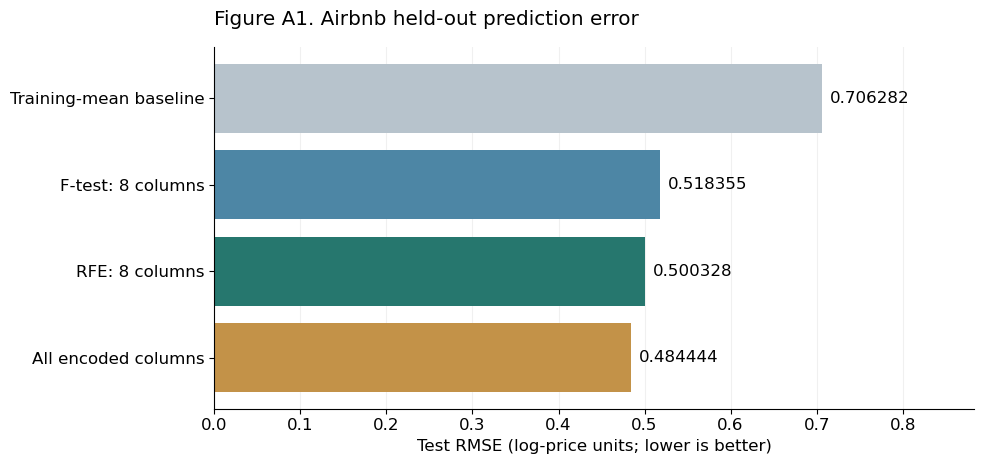

In [35]:
fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(performance_table["Model"], performance_table["Test RMSE"],
               color=["#b7c3cc", "#4d86a5", "#26776e", "#c39248"])
for bar, value in zip(bars, performance_table["Test RMSE"]):
    ax.text(value + 0.009, bar.get_y() + bar.get_height() / 2, f"{value:.6f}", va="center", fontsize=12)
ax.invert_yaxis()
ax.set_xlabel("Test RMSE (log-price units; lower is better)")
ax.set_xlim(0, performance_table["Test RMSE"].max() * 1.25)
ax.set_title("Figure A1. Airbnb held-out prediction error", loc="left", pad=16)
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

In [36]:
perf = performance_table.set_index("Model")
rmse_f = perf.loc["F-test: 8 columns", "Test RMSE"]
rmse_rfe = perf.loc["RFE: 8 columns", "Test RMSE"]
rmse_all = perf.loc["All encoded columns", "Test RMSE"]
relative_gap = (rmse_rfe / rmse_all - 1) * 100
display(Markdown(f"The eight-column F-test forest has RMSE **{rmse_f:.6f}**, while the RFE forest "
                 f"has **{rmse_rfe:.6f}** and the all-column forest **{rmse_all:.6f}**. "
                 f"RFE's RMSE is **{abs(relative_gap):.6f}%** {'higher' if relative_gap >= 0 else 'lower'} "
                 "than the all-column comparison. I judge the reduction in input columns against "
                 "that measured error difference, rather than assuming fewer features must predict better. "
                 "The all-column forest is a fixed benchmark here, not a model tuned on this test set."))

The eight-column F-test forest has RMSE **0.518355**, while the RFE forest has **0.500328** and the all-column forest **0.484444**. RFE's RMSE is **3.278843%** higher than the all-column comparison. I judge the reduction in input columns against that measured error difference, rather than assuming fewer features must predict better. The all-column forest is a fixed benchmark here, not a model tuned on this test set.

## A4 · Are the two ranking rules measuring the same evidence?

The correlation between `accommodates`, `bedrooms` and `beds` illustrates redundancy:
listing capacity is described several ways. I also count how many training rows support
each selected one-hot indicator. Those support counts help distinguish a frequently
observed signal from a small category. The counts use training rows, so the interpretation
does not retrospectively change the selection using test information.

In [37]:
capacity_corr = X_train[["accommodates", "bedrooms", "beds"]].corr()
capacity_table = capacity_corr.reset_index().rename(columns={"index": "Capacity feature"})
show_table(capacity_table, "Table A4. Training correlations among capacity measurements")
category_support = []
for name in union_names:
    if name not in numeric + binary:
        category_support.append({"Selected indicator": name, "Training rows with value 1": int(X_train[name].sum())})
show_table(pd.DataFrame(category_support), "Table A5. Training support for selected category indicators")

Capacity feature,accommodates,bedrooms,beds
accommodates,1.000000,0.722571,0.828606
bedrooms,0.722571,1.000000,0.729641
beds,0.828606,0.729641,1.000000


Selected indicator,Training rows with value 1
property_type_House,13143
cancellation_policy_flexible,16659
cancellation_policy_strict,23915
city_LA,15952
city_SF,4438


**What I take from the exercise.** Both selectors can favour capacity-related fields,
but correlated features do not represent independent sources of information. A forest
can divide importance across them or retain one as a substitute for another. An F test
cannot see these joint substitutions. This explains why agreement on some columns can
coexist with different selected lists, without either computation being wrong.

**Limits of the added checks.** The Airbnb split is a random listing split. It does
not test performance on a future period, an unseen city, or entirely different hosts.
The available fields do not include host IDs or timestamps for a stronger grouped or
temporal split. Review scores are missing for many listings; replacing them by a
median is reproducible, but it assumes a missing score can be represented by a
typical observed score. It can lose information about why a review is missing.
A missingness indicator could test that question in future work; I do not add it to
just one selector because that would change their shared candidate set.

The forest settings and the feature count are fixed, not exhaustively tuned. A single
held-out split has sampling variability, and a ranking is not proof of a price cause.
The conclusions therefore concern this dataset and these specified procedures.
For a business decision, I would next validate on the actual deployment population
and check errors by city and listing size before recommending pricing changes.

## References and reproducibility

The source of the assignment is the current Canvas file
`Week4_Feature_Engineering_Tutorial.ipynb`, obtained and checked on 30 September 2026.
The four questions contain 100 internal points; the Canvas assignment is worth 10 points.
The answer settings above fix the data split, preprocessing, classifier, forest and seeds.
The environment and hashes below make the exact local inputs identifiable.

Official API references (consulted 30 September 2026; sklearn 1.5 documentation):

- [ANOVA F statistic](https://scikit-learn.org/1.5/modules/generated/sklearn.feature_selection.f_classif.html)
- [SequentialFeatureSelector](https://scikit-learn.org/1.5/modules/generated/sklearn.feature_selection.SequentialFeatureSelector.html)
- [Univariate regression F test](https://scikit-learn.org/1.5/modules/generated/sklearn.feature_selection.f_regression.html)
- [Recursive feature elimination](https://scikit-learn.org/1.5/modules/generated/sklearn.feature_selection.RFE.html)
- [RandomForestRegressor](https://scikit-learn.org/1.5/modules/generated/sklearn.ensemble.RandomForestRegressor.html)

To rerun, open this notebook in Jupyter with pandas, NumPy, matplotlib, seaborn and
scikit-learn installed, keep the two data files in a recognised folder, and restart/run all.
The next cell checks selected counts and finite predictions and prints a compact result
record. A successful assertion confirms consistency, not a promised grade.

In [38]:
# Independently verify one ANOVA score and one regression F score against their formulas.
check_feature = "petal-L"
overall_mean = X_iris[check_feature].mean()
between = sum(len(group) * (group[check_feature].mean() - overall_mean) ** 2
              for _, group in iris_q.groupby("class"))
within = sum(((group[check_feature] - group[check_feature].mean()) ** 2).sum()
             for _, group in iris_q.groupby("class"))
manual_anova = (between / 2) / (within / 147)
assert np.isclose(manual_anova, anova_selector.scores_[iris_features.index(check_feature)])
r = correlations.loc["accommodates"]
manual_regression_f = (r ** 2 / (1 - r ** 2)) * (len(y_train) - 2)
assert np.isclose(manual_regression_f, f_selector.scores_[list(encoded_names).index("accommodates")])
print(f"Formula cross-check: petal-L ANOVA F = {manual_anova:.6f}; accommodates regression F = {manual_regression_f:.6f}")
assert len(anova_names) == len(sfs_names) == 2
assert len(f_names) == len(rfe_names) == 8
assert np.allclose(rfe.estimator_.predict(rfe.transform(X_test)), test_predictions["RFE: 8 columns"])
assert all(len(p) == len(y_test) and np.isfinite(p).all() for p in test_predictions.values())
input_records = []
for name in ["iris.txt", "Airbnb.csv", "Week4_Feature_Engineering_Tutorial.ipynb"]:
    path = DATA / name
    if path.exists():
        input_records.append({"File": name, "Bytes": path.stat().st_size,
                              "SHA-256": hashlib.sha256(path.read_bytes()).hexdigest()})
show_table(pd.DataFrame(input_records), "Input versions")
summary = {"q1_features": anova_names, "q2_features": sfs_names,
           "q3_features": f_names, "q4_features": rfe_names,
           "airbnb_rows": len(airbnb), "train_rows": len(y_train), "test_rows": len(y_test),
           "encoded_features": len(encoded_names), "shared_features": shared,
           "iris_selection_cv": float(selected_cv.mean()),
           "iris_nested_two": float(nested_two), "iris_nested_all": float(nested_all),
           "performance": performance_table.to_dict(orient="records"),
           "source_hashes": input_records,
           "python": platform.python_version(), "sklearn": sklearn.__version__}
print("Consistency checks passed. Q1–Q4 and Appendix A are complete.")

Formula cross-check: petal-L ANOVA F = 1179.034328; accommodates regression F = 27527.138022


File,Bytes,SHA-256
iris.txt,4700,b56cac2a035e9c2c4d3403c32eff8f44860c4c1006447abe6cb24b7eb003bcac
Airbnb.csv,5041771,429141448fed5ee5692550a040ee9ba13c43e7aafac680d5b1346fa1d094395b
Week4_Feature_Engineering_Tutorial.ipynb,475599,b41b08f5c22afb59286ad7c522e9cb0f70dc4de635b3a961298661d66c57376f


Consistency checks passed. Q1–Q4 and Appendix A are complete.
